In [1]:
import numpy as np

#Here we mainly focus on model selection, we follow validation based approach to select the best model. 
#We generate samples from an nth order polynomials and fit the generated data using different order polynomials.
##For example $y = W_3x^3 + W_2x_2 + W_1x + W_0$
### Generating data 'X' ranges between -10 to 10 
### 'Y' is a linear combination of parameters as Y = W'X+b+gaussian(0,epsilon)

In [2]:
W0_true = 11;W1_true = 4.5

W2_true = 3;W3_true = 4

Number_of_points = 1000

Number_of_training = int(Number_of_points*0.8)

Number_of_testing = int(Number_of_points*0.2)

In [3]:
def generate_data(Order):  
    W0 =  W0_true; W1 = W1_true; W2 = W2_true; W3 = W3_true

    if Order == 1:
        W2 = 0;W3 = 0
    elif Order == 2:
        W3 = 0
    
    X_data = np.linspace(-10,10,Number_of_points)
    
    Y_data = W3*np.power(X_data,3)+W2*X_data**2 + W1*X_data + W0 + np.random.normal(0,0.5,Number_of_points)
    
    return X_data,Y_data


In [4]:
def split_data(X_data,Y_data):
    
    index = np.random.permutation(Number_of_points)
    
    X_train = X_data[index[:Number_of_training]] 
    Y_train = Y_data[index[:Number_of_training]]
    
    X_test = X_data[index[Number_of_training:]]
    Y_test = Y_data[index[Number_of_training:]]
    
    return X_train,Y_train,X_test,Y_test
    

### Plot the data points

In [5]:
import matplotlib.pyplot as plt
def plot(x,y,title):
    fig,(ax1) = plt.subplots(1)
    if title!='Loss':
        ax1.plot(x,y,'x',markersize=3)
    else:
        ax1.plot(x,y)
        
    ax1.set_title(title, fontdict={'fontsize': 15, 'fontweight': 'medium'})
def plot_curve(x,y,W,title):
    fig,(ax1) = plt.subplots(1)
    ax1.plot(x,y,'x',markersize=3)
    ax1.set_title(title, fontdict={'fontsize': 15, 'fontweight': 'medium'})
    y = W[0] + W[1]*x +W[2]*x**2 + W[3]*x**3
    ax1.plot(x,y,'o')
    

    


In [6]:
def compute_loss(x, y, W):
    y_pred = W[0] + W[1]*x + W[2]*np.power(x, 2) + W[3]*np.power(x, 3)
    return np.sum(np.power(y_pred - y, 2)) / (2.0 * x.shape[0])

### Learning the parameters of the model for some 'N' epochs, by minimizing squared-difference error
$L(W) = \frac{1}{2}\Sigma_{n=1}^{N}(W^Tx_i - y_i)^2$

In [7]:
def fit(X_train, Y_train, Order, Epochs, learning_rate, Plot=False):
    N = X_train.shape[0]
    Loss = []
    
    X = np.ones((Order + 1, N))
    for i in range(1, Order + 1):
        X[i, :] = X_train ** i
        
    W = np.zeros((4, 1))
    for i in range(Order + 1):
        W[i, 0] = np.random.normal(0, 0.2)

    for epoch in range(Epochs):
        Y_pred = np.matmul(W[:Order + 1].T, X)
        error = Y_pred - Y_train
        
        dW = np.matmul(error, X.T).T
        W[:Order + 1] = W[:Order + 1] - (learning_rate * dW / N)
        
        current_loss = compute_loss(X_train, Y_train, W)
        Loss.append(current_loss)
        
        if epoch % 50 == 0 and Plot:
            print(f"Epoch: {epoch}/{Epochs} | Train loss: {current_loss:.4f}")
            plot_curve(X_train, Y_train, W, 'Training')

    if Plot:
        plot(range(len(Loss)), Loss, 'Loss')
        
    return W

#### Generating and Splitting the data
1. generate_data(order) samples data from a polynomial of 'order' passed as an argument
2. split_data(X,Y), splits the data into training and testing 

(800,)


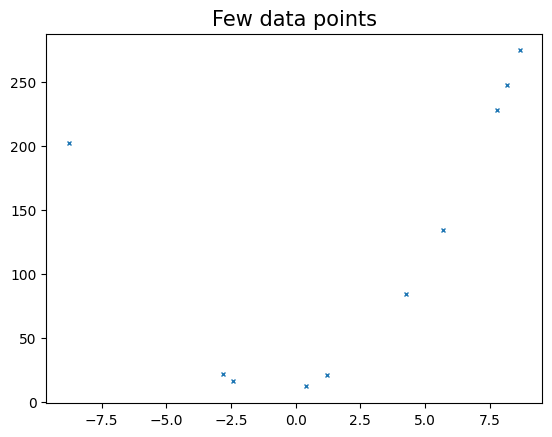

In [8]:
gen_order = 2 #1,2,3
X_data , Y_data = generate_data(gen_order)
X_train,Y_train,X_test,Y_test = split_data(X_data,Y_data)
print(X_train.shape)
plot(X_train[0:10],Y_train[0:10],'Few data points')

Epoch: 0/1000 | Train loss: 9171.9980
Epoch: 50/1000 | Train loss: 1264.7780
Epoch: 100/1000 | Train loss: 239.5105
Epoch: 150/1000 | Train loss: 104.1364
Epoch: 200/1000 | Train loss: 86.0114
Epoch: 250/1000 | Train loss: 83.3361
Epoch: 300/1000 | Train loss: 82.6978
Epoch: 350/1000 | Train loss: 82.3294
Epoch: 400/1000 | Train loss: 81.9981
Epoch: 450/1000 | Train loss: 81.6731
Epoch: 500/1000 | Train loss: 81.3504
Epoch: 550/1000 | Train loss: 81.0295
Epoch: 600/1000 | Train loss: 80.7103
Epoch: 650/1000 | Train loss: 80.3928
Epoch: 700/1000 | Train loss: 80.0769
Epoch: 750/1000 | Train loss: 79.7627
Epoch: 800/1000 | Train loss: 79.4501
Epoch: 850/1000 | Train loss: 79.1391
Epoch: 900/1000 | Train loss: 78.8298
Epoch: 950/1000 | Train loss: 78.5221
Final parameter values  : W0 = [0.68322574] , W1 = [-0.02708218], W2 = [3.17425725], W3 = [0.06343066]
Test_loss : 79.61738225803309


C:\Users\anubh\AppData\Local\Temp\ipykernel_13932\1116106838.py:3: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig,(ax1) = plt.subplots(1)


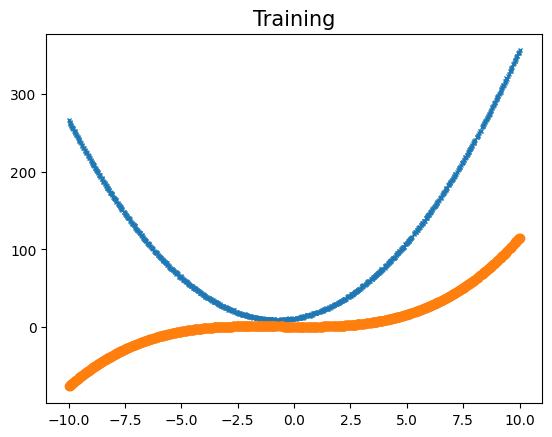

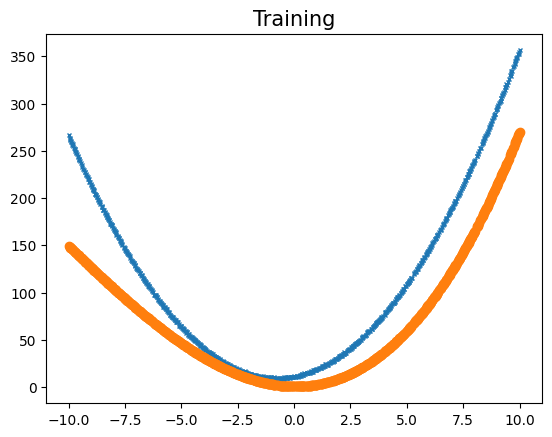

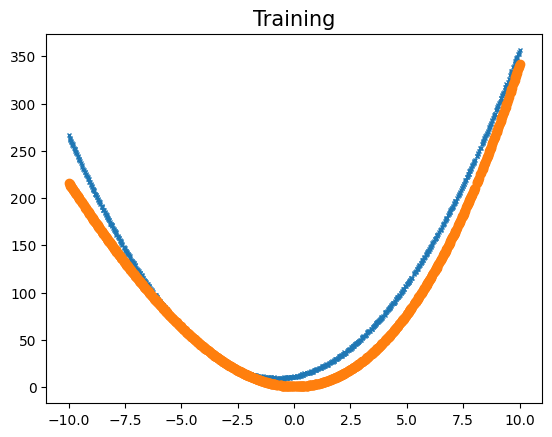

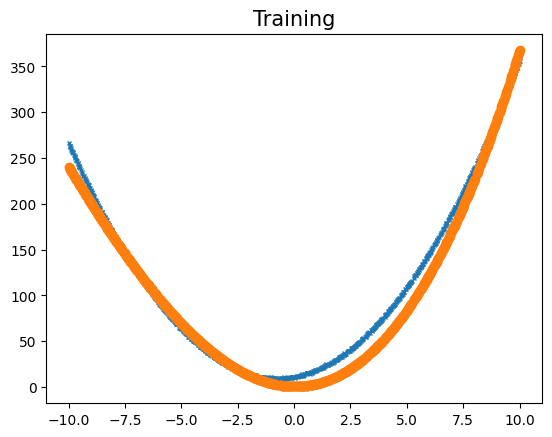

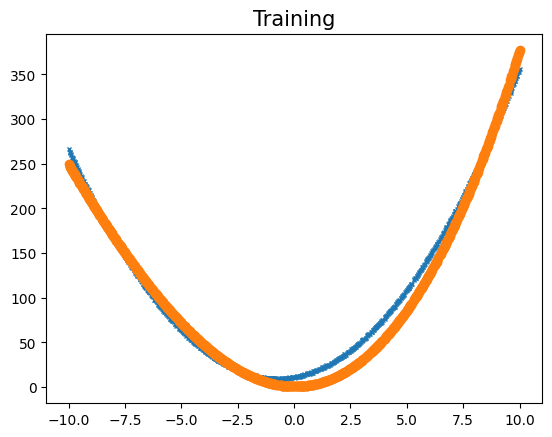

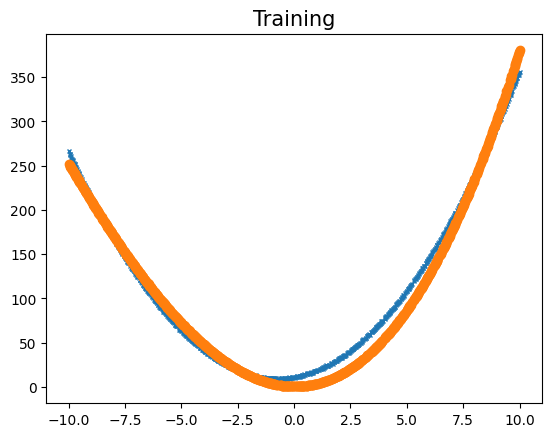

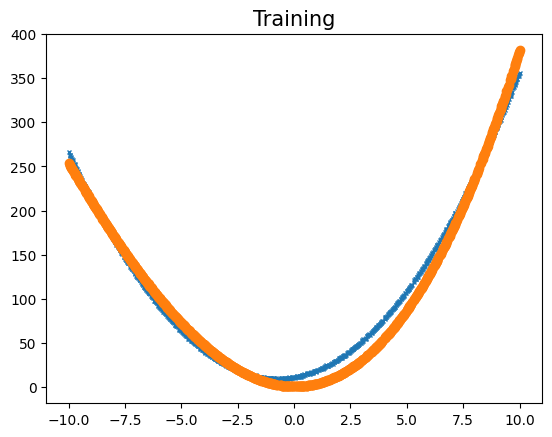

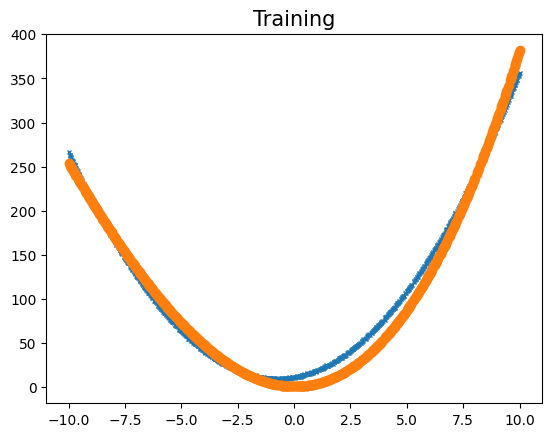

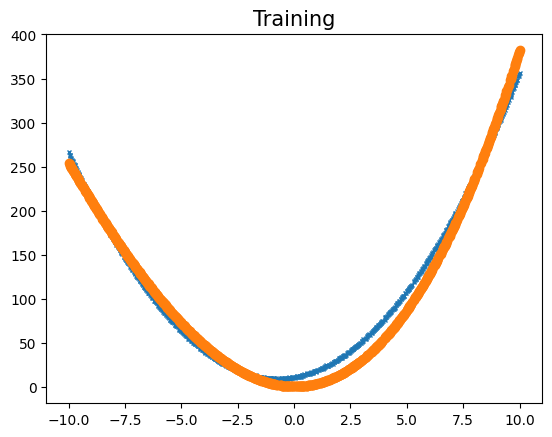

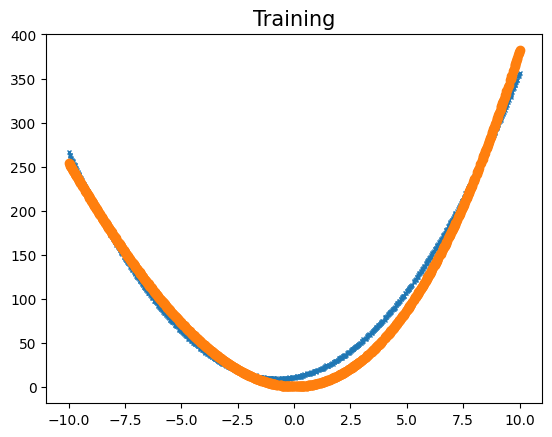

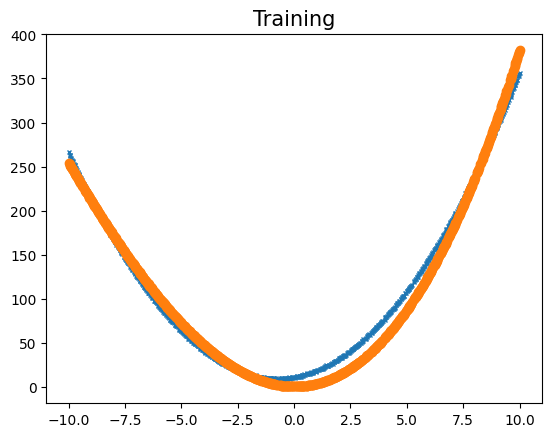

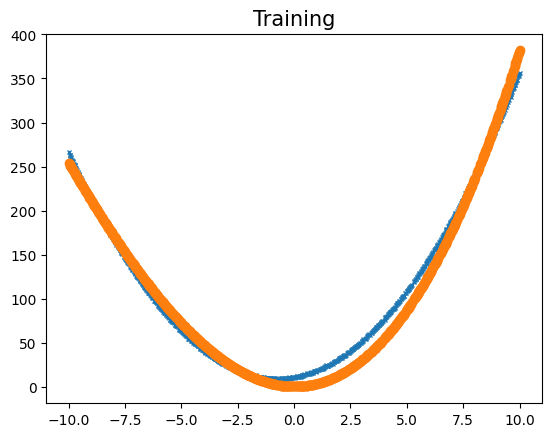

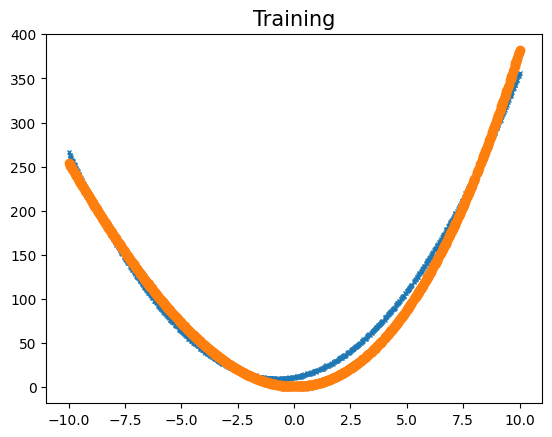

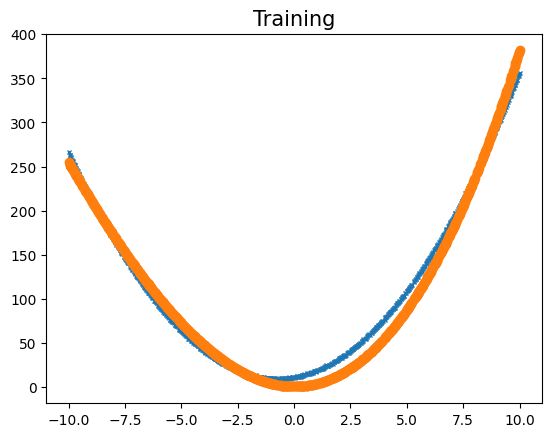

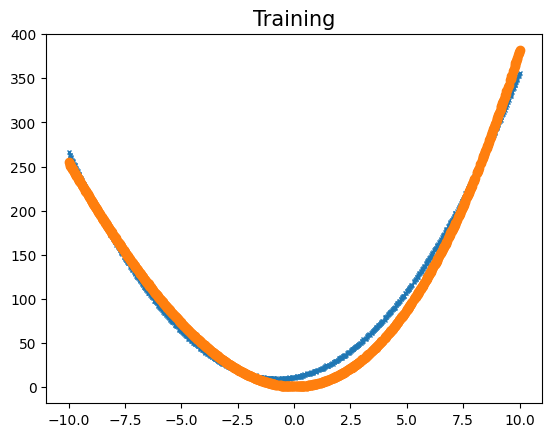

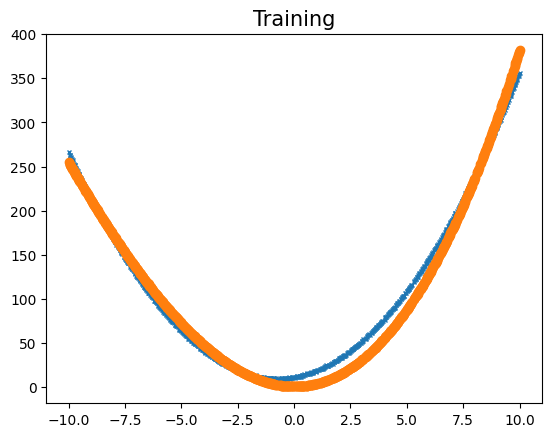

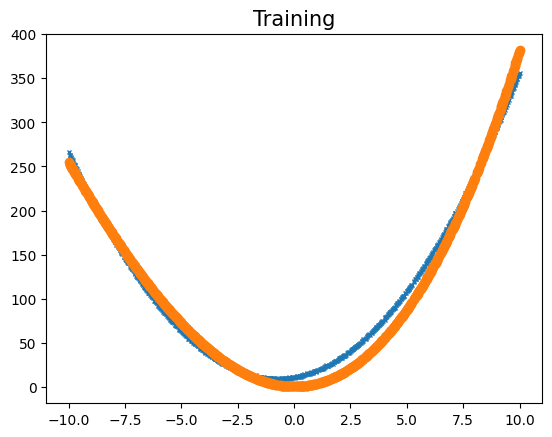

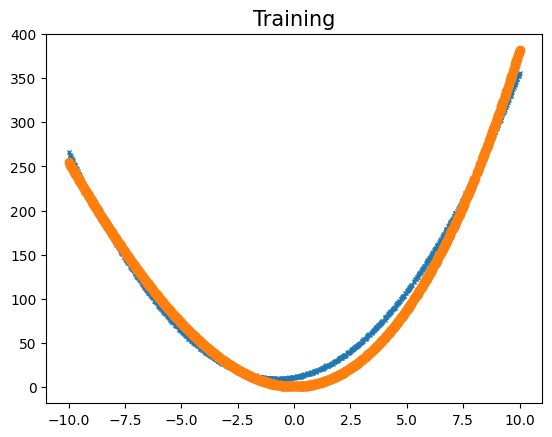

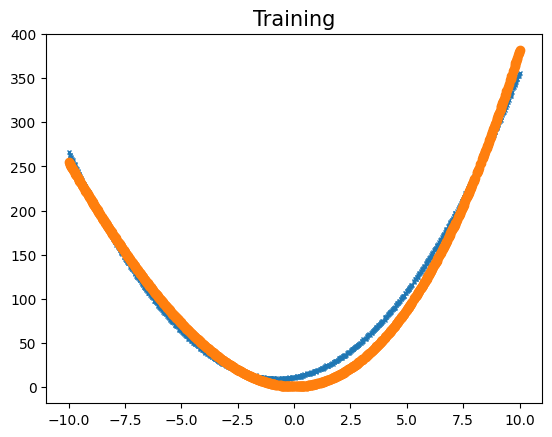

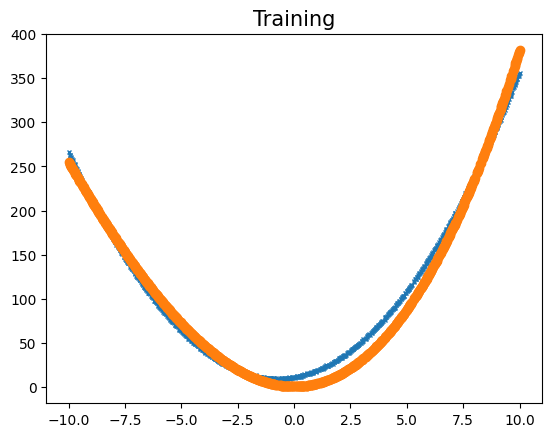

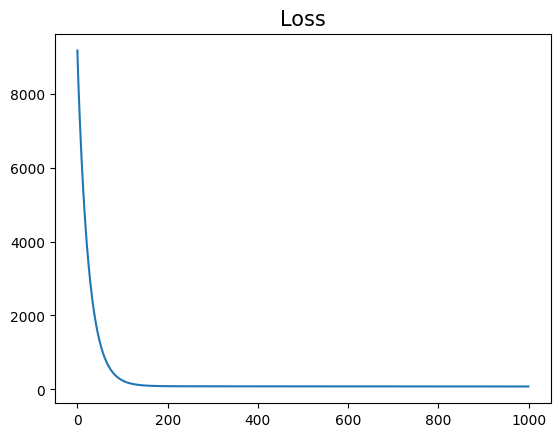

In [9]:
fit_order = 3 #1,2,3
learning_rate = [ 0.001 ,0.0001, 0.00001]
Epochs = 1000
W = fit(X_train,Y_train,fit_order,Epochs,learning_rate[fit_order-1],True)

print("Final parameter values  : W0 = "+str(W[0])+" , W1 = "+str(W[1])+", W2 = "+str(W[2])+", W3 = "+str(W[3]))
print("Test_loss : "+str(compute_loss(X_test,Y_test,W)))

In [10]:
def validation_set(X_train,Y_train,start,end):
    X_valid = X_train[start:end]
    Y_valid = Y_train[start:end]
    
    X_train1 = X_train[0:start]
    X_train1 = np.concatenate((X_train1,X_train[end:]))
    
    Y_train1 = Y_train[0:start]
    Y_train1 = np.concatenate((Y_train1,Y_train[end:]))
    
    return X_train1,Y_train1,X_valid,Y_valid
    
    
    
    

### We are performing a 5-fold cross validation  to select a model

In [12]:
K = 5
valid_size = int(Number_of_training * 0.2)
Model_loss = np.zeros((3,1))
for i in range(K):
    #Splitting the training data into training and validation dataset
    X_train1,Y_train1,X_valid,Y_valid  = validation_set(X_train,Y_train,valid_size*i,valid_size*(i+1))
    for Order in range(1,4):
        W = fit(X_train1,Y_train1,Order,Epochs,learning_rate[Order-1],False)
        Model_loss[Order-1] += compute_loss(X_valid,Y_valid,W)
Order = np.argmin(Model_loss)
print("For data generated using %2d order polynomial, best order polynomial is %2d "%(gen_order,Order+1))
        
        
        
    


For data generated using  2 order polynomial, best order polynomial is  2 


In [13]:
Model_loss

array([[24223.52814996],
       [  125.68809439],
       [  396.37355416]])

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=gen_order)
X_poly = poly.fit_transform(X_train.reshape(-1, 1))

reg = LinearRegression(fit_intercept=False).fit(X_poly, Y_train)
print(reg.score(X_poly, Y_train))

D:\miniconda3\envs\cs229\Lib\site-packages\sklearn\utils\_param_validation.py:11: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 2.4.6)
  from scipy.sparse import csr_matrix, issparse


0.9999717451167832
